In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.optimize import curve_fit

## Exercice 1

2)

In [3]:
def matrix_and_vector(N,f,alpha,beta):
    h = 1/(N+1)
    F = np.zeros(N)
    for i in range(N):
        F[i] = f(i*h)
    A = 1/(h**2)*(2*np.diag(np.ones(N),0) - np.diag(np.ones(N-1),1) - np.diag(np.ones(N-1),-1))
    F[0] += alpha/(h**2)
    F[N-1] += beta/(h**2)
    return A,F

3) a)

In [5]:
def u(x):
    return (x*(1-x))/2

In [7]:
def f(x):
    return 1

3) b)

Vecteur inconnu $U_h$ :

In [9]:
def linear_system(N,f,alpha,beta):
    A,F = matrix_and_vector(N,f,alpha,beta)
    return np.linalg.solve(A,F)

linear_system(5,f,0,0)

array([0.06944444, 0.11111111, 0.125     , 0.11111111, 0.06944444])

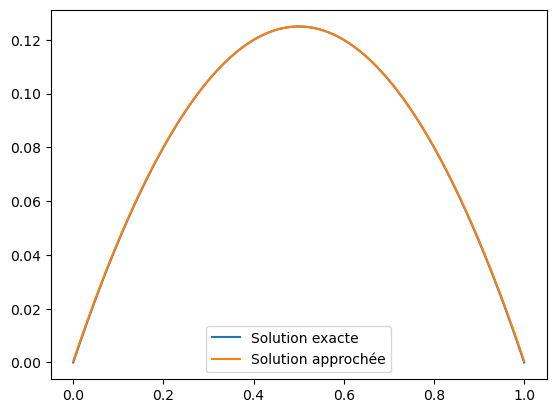

In [11]:
alpha = 0
beta = 0
L1 = []
L2 = []
L3 = []
N = 1000
x = np.linspace(0,1,N)
ord1 = u(x)
ord2 = linear_system(N,f,alpha,beta)
plt.plot(x,ord1,label="Solution exacte")
plt.plot(x,ord2,label="Solution approchée")
plt.legend()
plt.show()

In [19]:
def norm_inf1(u):
    diff = np.abs(u)
    return np.max(diff)

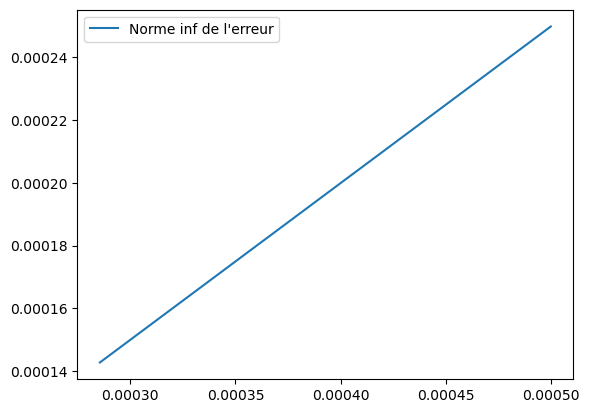

In [21]:
alpha = 0
beta = 0
abs = []
ord = []
quad = []
for N in [2000,2500,3000,3500]:
    h = 1/(N+1)
    x = np.linspace(0,1,N)
    uexacte = u(x)
    uapprox = linear_system(N,f,alpha,beta)
    diff = uapprox - uexacte
    err = norm_inf1(diff)
    abs.append(h)
    ord.append(err)
plt.plot(abs,ord,label="Norme inf de l'erreur")
plt.legend()
plt.show()

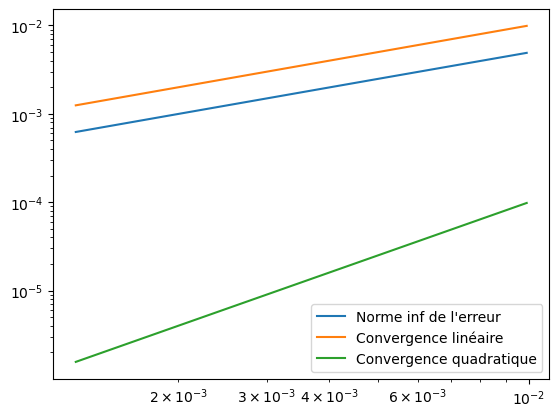

In [23]:
alpha = 0
beta = 0
abs = []
ord = []
quad = []
for N in [100,200,500,800]:
    h = 1/(N+1)
    x = np.linspace(0,1,N)
    uexacte = u(x)
    uapprox = linear_system(N,f,alpha,beta)
    diff = uapprox - uexacte
    err = norm_inf1(diff)
    abs.append(h)
    ord.append(err)
    quad.append(h**2)
plt.loglog(abs,ord,label="Norme inf de l'erreur")
plt.loglog(abs,abs,label="Convergence linéaire")
plt.loglog(abs,quad,label="Convergence quadratique")
plt.legend()
plt.show()

Nous remarquons que la convergence de l'erreur en norme infini suit une tendance linéaire. Cela ne coincide pas avec les résultats du cours assurant une convergence d'ordre 2 i.e quadratique

4) b)

In [55]:
def u_2(x):
    return np.exp(-4*x)*np.sin(np.pi*x)

In [57]:
def f_2(x):
    return -(np.exp(-4*x) * ((16 - np.pi**2) * np.sin(np.pi*x) - 8 * np.pi * np.cos(np.pi*x)))

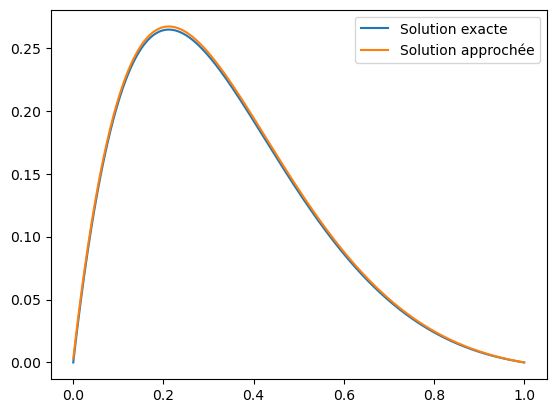

In [59]:
alpha2 = 0
beta2 = np.exp(-4)*np.sin(np.pi)
N = 1000
x = np.linspace(0,1,N)
ord1 = u_2(x)
ord2 = linear_system(N,f_2,alpha2,beta2)
plt.plot(x,ord1,label="Solution exacte")
plt.plot(x,ord2,label="Solution approchée")
plt.savefig("courbe")
plt.legend()
plt.show()

In [61]:
def norm_2(N):
    h = 1 / (N + 1)
    x = np.linspace(0, 1, N)
    u_exact = u_2(x)
    u_approx = linear_system(N, f_2, alpha2, beta2)
    diff = u_exact - u_approx
    s = np.sum(diff ** 2)
    return np.sqrt(h*s)

In [63]:
def norm_1(N):
    h = 1 / (N + 1)
    x = np.linspace(0, 1, N)
    u_exact = u_2(x)
    u_approx = linear_system(N, f_2, alpha2, beta2)
    diff = np.abs(u_exact - u_approx)
    s = np.sum(diff)
    return h * s

In [65]:
def norm_inf(N):
    h = 1/(N+1)
    x = np.linspace(0,1,N)
    u_exact = u_2(x)
    u_approx = linear_system(N, f_2, alpha2, beta2)
    diff = np.abs(u_exact - u_approx)
    return np.max(diff)

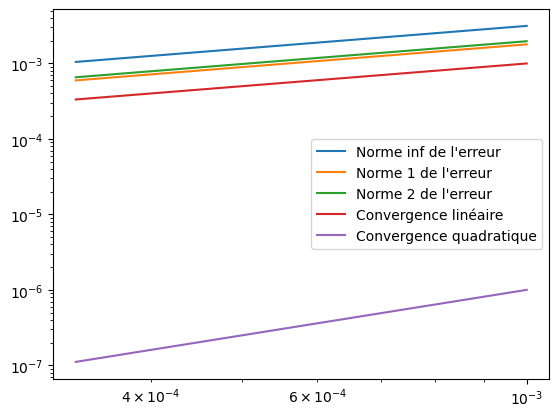

Temps d'exécution: 1.051314353942871 secondes


In [67]:
start_time = time.time()

abs2 = []
ord2 = []
ord3 = []
ord4 = []
lin = []
quad = []
for N in [1000,2000,3000]:
    h = 1/(N+1)
    norminf = norm_inf(N)
    norm1 = norm_1(N)
    norm2 = norm_2(N)
    abs2.append(h)
    ord2.append(norminf)
    ord3.append(norm1)
    ord4.append(norm2)
    lin.append(1/N)
    quad.append(1/(N**2))
plt.loglog(abs2,ord2,label="Norme inf de l'erreur")
plt.loglog(abs2,ord3,label="Norme 1 de l'erreur")
plt.loglog(abs2,ord4,label="Norme 2 de l'erreur")
plt.loglog(abs2,lin,label="Convergence linéaire")
plt.loglog(abs2,quad,label="Convergence quadratique")
plt.savefig("tp2")
plt.legend()
plt.show()

end_time = time.time()
execution_time = end_time - start_time
print("Temps d'exécution:", execution_time, "secondes")

Déterminer les coefficients directeurs des droites en loglog :

In [31]:
def fonction_affine(x,a,b):
    return a*x + b

In [87]:
def fonction_polynome(x,a,b,c):
    return a*x**2 + b*x + c

In [33]:
xdata = np.log(abs2)
ydata = np.log(ord2)
popt, pcov = curve_fit(fonction_affine, xdata, ydata)
popt[0]

1.00184086092992

Etrange que les convergences des normes $\infty$ ,$1$,$2$ soient toutes linéaires

## Exercice 2

1)

In [47]:
def matrix_and_vector2(N,f,alpha,beta):
    h = 1/(N+1)
    F = np.zeros(N)
    for i in range(N):
        F[i] = f(i*h)
    A = (1/(h**2))*((2-(np.pi)**2*h**2)*np.diag(np.ones(N),0) - np.diag(np.ones(N-1),1) - np.diag(np.ones(N-1),-1))
    F[0] += alpha/h**2
    F[N-1] += beta/h**2
    return A,F

matrix_and_vector2(5,f,alpha,beta)[0]

array([[ 62.1303956, -36.       ,   0.       ,   0.       ,   0.       ],
       [-36.       ,  62.1303956, -36.       ,   0.       ,   0.       ],
       [  0.       , -36.       ,  62.1303956, -36.       ,   0.       ],
       [  0.       ,   0.       , -36.       ,  62.1303956, -36.       ],
       [  0.       ,   0.       ,   0.       , -36.       ,  62.1303956]])

2)

In [55]:
def linear_system2(N,f,alpha,beta):
    A,F = matrix_and_vector2(N,f,alpha,beta)
    return np.linalg.solve(A,F)

In [57]:
N_list = [5, 10, 15, 20]

min_values = []
det = []
cond = []

for N in N_list:
    approx = linear_system2(N, f, alpha, beta)
    min_value = np.min(approx)
    min_values.append(min_value)
    
    matrix = matrix_and_vector2(N, f, alpha, beta)[0]
    det.append(np.linalg.det(matrix))
    cond.append(np.linalg.cond(matrix))

print("Valeur minimale prise par l'approximation pour chaque valeur de N :", min_values)
print("Déterminant de la matrixe $A_h$ pour chaque valeur de N :", det)
print("Conditionnement de la matrixe $A_h$ pour chaque valeur de N :", cond)

Valeur minimale prise par l'approximation pour chaque valeur de N : [-5.572376145873587, -18.713187412613145, -40.081240375281276, -68.90577415842178]
Déterminant de la matrixe $A_h$ pour chaque valeur de N : [-4431147.526228283, -2.5646643752509264e+19, -3.44793930148543e+34, -1.5238929049545457e+51]
Conditionnement de la matrixe $A_h$ pour chaque valeur de N : [557.1422342542668, 6940.206647940959, 31713.19592233633, 94833.1810629162]
